Epoch 1/50


/tmp/ipykernel_1778/1286631173.py:47: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data[numeric_features] = data[numeric_features].fillna(method='ffill')
/tmp/ipykernel_1778/1286631173.py:48: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data[numeric_features] = data[numeric_features].fillna(method='bfill')
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


124/124 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0246 - val_loss: 0.0117
Epoch 2/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0125 - val_loss: 0.0091
Epoch 3/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0106 - val_loss: 0.0091
Epoch 4/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0101 - val_loss: 0.0085
Epoch 5/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0092 - val_loss: 0.0073
Epoch 6/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0088 - val_loss: 0.0115
Epoch 7/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0084 - val_loss: 0.0084
Epoch 8/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0080 - val_loss: 0.0075
Epoch 9/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0078 - val_loss: 0.0065
Epoch 10/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0077 - val_loss: 0.0085
Epoch 11/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0074 - val_loss: 0.0075
Epoch 12/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0

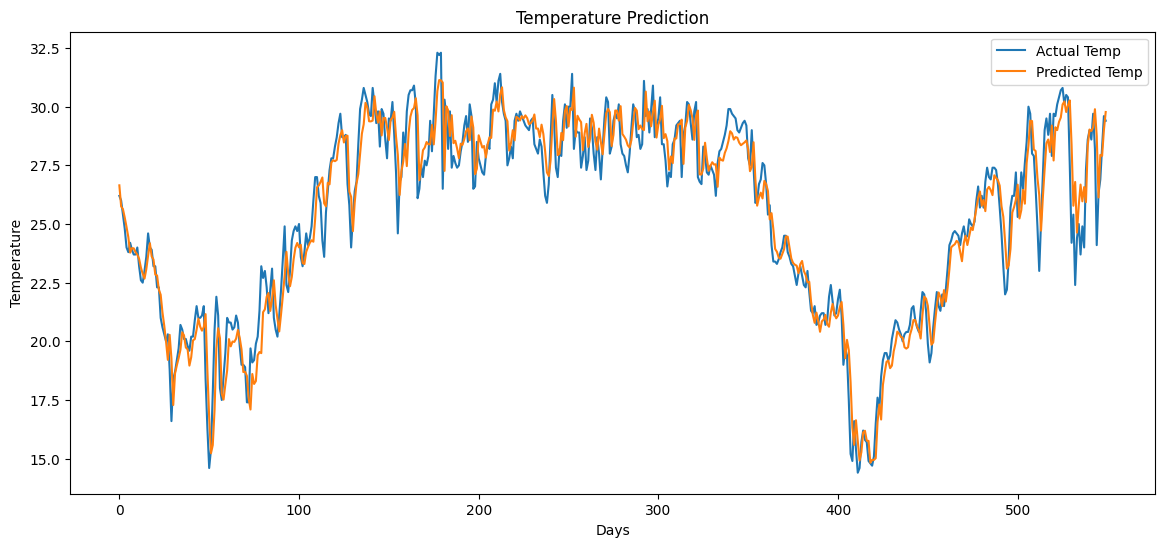

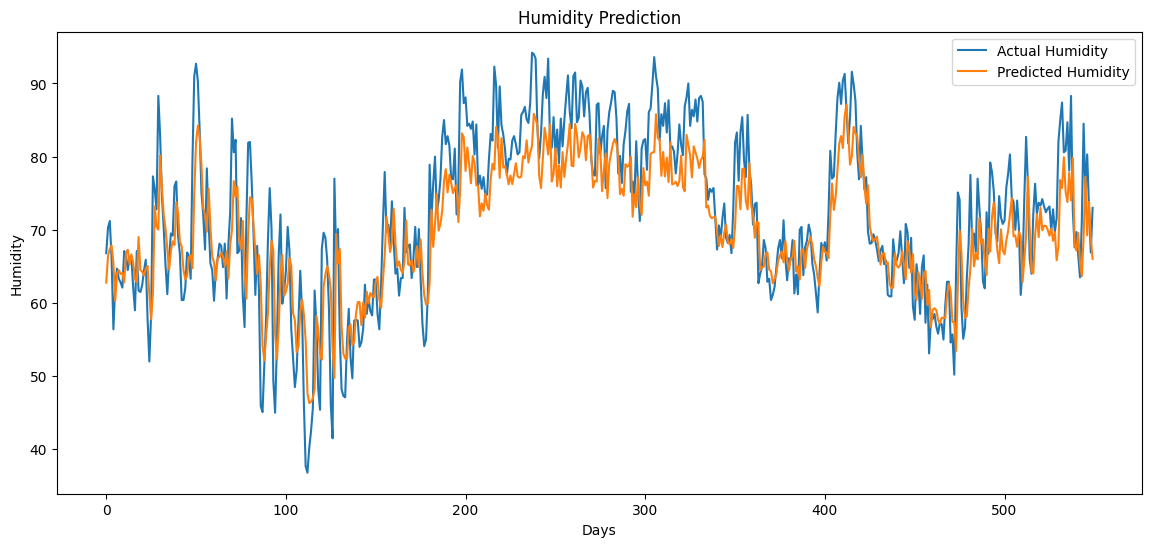

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Next 7 Days Weather Forecast:
        date  pred_temp  pred_humidity    pred_condition
0 2026-05-17  30.241547      69.685959  Partially cloudy
1 2026-05-18  30.805729      68.678963  Partially cloudy
2 2026-05-19  31.243252      68.909187  Partially cloudy
3 2026-05-20  31.516018      69.589485  Partially cloudy
4 2026-05-21  31.679384      70.218048  Partially cloudy
5 2026-05-22  31.740545      70.663033  Partially cloudy
6 2026-05-23  31.729406      70.916855  Partially cloudy


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
 import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import matplotlib.pyplot as plt

# ===============================
# Step 1: Load dataset
# ===============================
file_path = "/content/CanSAT_Weather_Merged_2018_2026.xlsx"
data = pd.read_excel(file_path, sheet_name="Merged_Data")

data.rename(columns={'datetime':'date'}, inplace=True)
data['date'] = pd.to_datetime(data['date'])

# ===============================
# Step 2: Feature engineering
# ===============================
# Cyclical encoding for month/day-of-week
data['month'] = data['date'].dt.month
data['dayofweek'] = data['date'].dt.dayofweek
data['month_sin'] = np.sin(2*np.pi*data['month']/12)
data['month_cos'] = np.cos(2*np.pi*data['month']/12)
data['dow_sin'] = np.sin(2*np.pi*data['dayofweek']/7)
data['dow_cos'] = np.cos(2*np.pi*data['dayofweek']/7)

# Encode conditions for classification
le_conditions = LabelEncoder()
data['condition_encoded'] = le_conditions.fit_transform(data['conditions'])

# ===============================
# Step 3: Prepare features
# ===============================
numeric_features = ['temp', 'tempmax', 'tempmin', 'feelslike', 'humidity',
                    'sealevelpressure', 'solarradiation', 'aqius', 'aqielement',
                    'month_sin', 'month_cos', 'dow_sin', 'dow_cos']

targets = ['temp','humidity']

# Convert columns to numeric, coercing errors to NaN
for col in numeric_features:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Fill missing values using ffill then bfill to catch all NaNs
data[numeric_features] = data[numeric_features].fillna(method='ffill')
data[numeric_features] = data[numeric_features].fillna(method='bfill')

# Remove any columns that are still all NaNs after imputation
# This handles cases where a column was entirely NaN from the start or after coercion
original_numeric_features_count = len(numeric_features)
numeric_features = [col for col in numeric_features if not data[col].isnull().all()]
if len(numeric_features) < original_numeric_features_count:
    print(f"Warning: Dropped {original_numeric_features_count - len(numeric_features)} feature columns that were entirely NaN after imputation.")


# Scale features
scaler_X = MinMaxScaler()
scaled_X = scaler_X.fit_transform(data[numeric_features])

scaler_y = MinMaxScaler()
scaled_y = scaler_y.fit_transform(data[targets])

# ===============================
# Step 4: Create LSTM sequences for multi-output regression
# ===============================
seq_length = 7
X_seq, y_seq = [], []
for i in range(seq_length, len(scaled_X)):
    X_seq.append(scaled_X[i-seq_length:i])
    y_seq.append(scaled_y[i])
X_seq, y_seq = np.array(X_seq), np.array(y_seq)

split_index = int(len(X_seq)*0.8)
X_train, X_test = X_seq[:split_index], X_seq[split_index:]
y_train, y_test = y_seq[:split_index], y_seq[split_index:]

# ===============================
# Step 5: Build LSTM model for temp + humidity
# ===============================
model = Sequential()
model.add(LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dropout(0.2))
model.add(Dense(len(targets)))
model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=50, batch_size=16, validation_split=0.1, verbose=1)

# Predict on test
y_pred = model.predict(X_test)
y_test_inv = scaler_y.inverse_transform(y_test)
y_pred_inv = scaler_y.inverse_transform(y_pred)

# Plot temperature
plt.figure(figsize=(14,6))
plt.plot(y_test_inv[:,0], label='Actual Temp')
plt.plot(y_pred_inv[:,0], label='Predicted Temp')
plt.xlabel('Days')
plt.ylabel('Temperature')
plt.title('Temperature Prediction')
plt.legend()
plt.show()

# Plot humidity
plt.figure(figsize=(14,6))
plt.plot(y_test_inv[:,1], label='Actual Humidity')
plt.plot(y_pred_inv[:,1], label='Predicted Humidity')
plt.xlabel('Days')
plt.ylabel('Humidity')
plt.title('Humidity Prediction')
plt.legend()
plt.show()

# ===============================
# Step 6: Train Random Forest for conditions
# ===============================
condition_features = numeric_features
X_cond = data[condition_features]
y_cond = data['condition_encoded']
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_cond, y_cond)

# ===============================
# Step 7: Predict next 7 days
# ===============================
last_seq = scaled_X[-seq_length:]
future_preds = []
seq_input = np.copy(last_seq)

future_conditions = []

for _ in range(7):
    # LSTM for temp + humidity
    pred_scaled = model.predict(seq_input.reshape(1, seq_length, len(numeric_features)))
    pred = scaler_y.inverse_transform(pred_scaled)[0]
    future_preds.append(pred)

    # Random Forest for condition
    last_row_features = seq_input[-1].reshape(1,-1)
    cond_pred_encoded = rf_model.predict(last_row_features)
    cond_pred = le_conditions.inverse_transform(cond_pred_encoded)[0]
    future_conditions.append(cond_pred)

    # Update sequence: remove first row, append new prediction
    new_row = np.copy(seq_input[-1])
    # Replace temp and humidity with predicted values
    # Note: Ensure the indices for temp and humidity in 'numeric_features' match their positions in 'pred'
    # Assuming 'temp' is the 0th element and 'humidity' is the 4th element in numeric_features as per the original list.
    # If the order of numeric_features changes due to dropping columns, these indices need to be dynamically adjusted.
    # For now, we use fixed indices based on the original full numeric_features list.
    # More robust would be to find the index using numeric_features.index('temp') etc.
    try:
        temp_idx = numeric_features.index('temp')
        humidity_idx = numeric_features.index('humidity')
        new_row[temp_idx] = pred_scaled[0, 0] # pred_scaled is already scaled
        new_row[humidity_idx] = pred_scaled[0, 1] # pred_scaled is already scaled
    except ValueError:
        # Handle case where 'temp' or 'humidity' might have been dropped, though unlikely for targets
        print("Warning: 'temp' or 'humidity' not found in selected numeric_features after dropping NaN columns.")
        # Fallback: if temp/humidity are dropped, it indicates a critical data issue, or they aren't features anymore.
        # For now, if not found, we assume their original positions for new_row, but this is a potential issue.
        if 'temp' not in numeric_features: new_row[0] = pred_scaled[0, 0]
        if 'humidity' not in numeric_features: new_row[4] = pred_scaled[0, 1]

    seq_input = np.vstack([seq_input[1:], new_row])

future_dates = pd.date_range(start=data['date'].iloc[-1]+pd.Timedelta(days=1), periods=7)
future_df = pd.DataFrame({
    'date': future_dates,
    'pred_temp': [f[0] for f in future_preds],
    'pred_humidity': [f[1] for f in future_preds],
    'pred_condition': future_conditions
})

print("Next 7 Days Weather Forecast:")
print(future_df)